# 04 composite index

Calculate an equal-weight, directed min-max composite score. Higher means greater measured disadvantage.

Technical evidence for the confirmed Bremen project. Primary comparison: 2024 Ortsteile. No historical change claim; original data preserved.

## Setup and relative paths

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'analysis_common.py').exists(), 'Run from root or notebooks directory'
sys.path.insert(0, str(ROOT / 'src'))
from analysis_common import load_analysis, FEATURES
def read(relative):
    return pd.read_csv(ROOT / relative, dtype={'geo_code': str})
def show_figure(name):
    display(Image(filename=str(ROOT / 'results' / 'figures' / name)))


## Data loading and preparation

In [2]:
from composite_index import run, normalize, calculate
frame = load_analysis()

## Calculation and validation

In [3]:
results = run()
display(results.head(15))
display(read('results/composite_normalized_indicators.csv').head())
assert results.composite_score.between(0,1).all()
assert results.composite_score.is_monotonic_decreasing

,geo_code,geo_name,year,composite_score,rank
70,443,Ohlenhof,2024,0.942792,1
69,442,Gröpelingen,2024,0.876462,2
79,522,Grohn,2024,0.821318,3
83,531,Blumenthal,2024,0.795033,4
68,441,Lindenhof,2024,0.776568,5
48,373,Tenever,2024,0.768808,6
85,533,Lüssum-Bockhorn,2024,0.723830,7
20,243,Kirchhuchting,2024,0.708487,8
1,112,Bahnhofsvorstadt,2024,0.698170,9
82,525,Fähr-Lobbendorf,2024,0.693012,10


,geo_code,geo_name,year,unemployment,employment,benefit_receipt
0,111,Altstadt,2024,0.293500,0.318460,0.350266
1,112,Bahnhofsvorstadt,2024,0.708244,0.636539,0.749727
2,113,Ostertor,2024,0.286558,0.583977,0.232879
3,211,Alte Neustadt,2024,0.328075,0.338051,0.306961
4,212,Hohentor,2024,0.463787,0.486050,0.464658


## Results, visualization and interpretation

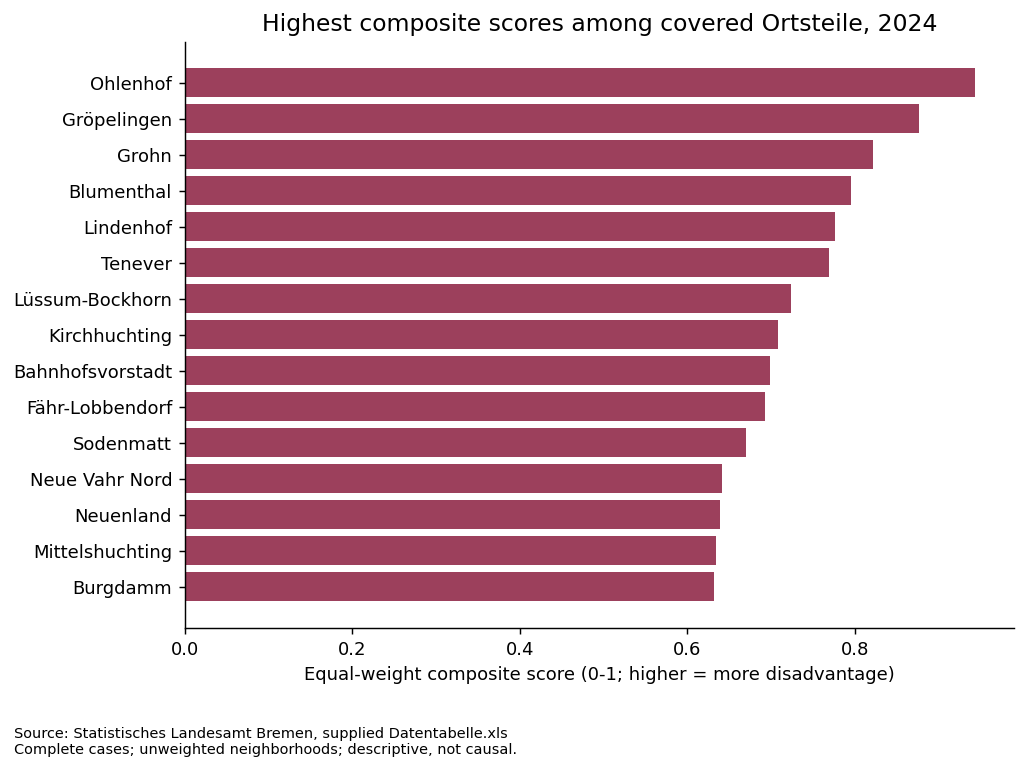

Equal weights are 1/3 per indicator. Employment is reversed. Scores use observed sample endpoints. See ../docs/methods.md for formulas and compensability assumptions.

In [4]:
show_figure('composite_ranking.png')
display(Markdown('Equal weights are 1/3 per indicator. Employment is reversed. Scores use observed sample endpoints. See ../docs/methods.md for formulas and compensability assumptions.'))

## Assumptions and limits

Complete-case scoring; no imputation. Different indicator denominators, correlated labour-market measures, unavailable 2024 income, unknown exact reference dates and incomplete historical boundary/definition metadata limit interpretation. Rankings apply only to the covered sample. Clusters are nominal. See analysis/dataset_validation.md and docs/methods.md. Tables are exported by reusable scripts; important figures appear in results/figures/.